# `Wall` — full design walkthrough

This notebook exercises the **entire public API** of the `Wall` element of
`design/` (ACI 318‑25), following one **canonical 12‑step flow**. Every element
— `Beam`, `Column`, `Wall`, `BeamColumnJoint` — shares this same skeleton, so the
*architecture* is identical and only the **physics** changes.

> **Rational structure.** The element is an immutable object. You *create* it,
> *run* it to cache capacities, *review* a given reinforcement against demands,
> let it *design* a proposal, and *adopt* that proposal by producing a **new**
> element. Reporting and plotting sit on top. The shared base class
> `design.common.element_base.ElementBase` provides the parts that are identical
> across elements (`apply`, `set_units`); the runtime `Element` protocol
> (`design.common.contracts`) is the canonical `isinstance` test.

### The 12‑step contract

| Step | Call | Purpose |
|------|------|---------|
| 1 | `Concrete(...)`, `Steel(...)` | materials (MPa) |
| 2 | `Wall.rectangular(...)` | **create** — every input argument shown |
| 3 | `el.run()` | lazy‑compute + cache capacity (returns `self`) |
| 4 | `el.capacity()` | capacity of the **as‑built** reinforcement |
| 5 | `el.demands(...)` | build the load set (display units → internal) |
| 6 | `el.check(demands)` | **review** the current rebar → PASS/FAIL |
| 7 | `el.design(demands)` | automatic **proposal** (multiple modes) |
| 8 | `results.envelope.<field>` | read the result **explicitly** (no magic) |
| 9 | `el.evolve(p)` / `el.apply(p)` | adopt → **new immutable** element |
| 10 | `report()` / `summary()` / `set_units()` / `print_final()` | reporting |
| 11 | `el.plot.*` | plotting |
| 12 | `el.run_optimize(demands)` | sweep detailing alternatives |

**Physics of this element.** A structural wall is a **web + boundary elements** composition (ACI §18.10). Each boundary element **is a real `Column`**, so the wall reuses the full column machinery (`Ash`, hoops, `hx`, `Mpr`, `Ve`) for its BEs.

**By‑design exceptions.** `design()` is **iterative**: with `auto_update=True` it rebuilds the BE geometry and re‑solves the PMM until the BE length converges. `WallDesignResults` has **no attribute proxy** — read `results.envelope.<field>`.

> **Internal units (non‑negotiable):** stress = MPa, length = mm, force = kN,
> moment = kN·m, area = mm². The `units=` argument only controls *presentation*.


## Step 1 — Materials

In [1]:
# Notebook setup: inline figures, repo on sys.path, silence the metre→mm warning
%matplotlib inline
import sys, pathlib, warnings
warnings.simplefilter("ignore", DeprecationWarning)

# Make `design` importable whether or not the repo is pip-installed:
_root = pathlib.Path.cwd().resolve()
while _root != _root.parent and not (_root / "design" / "__init__.py").is_file():
    _root = _root.parent
if (_root / "design").is_dir() and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from design.common.materials import Concrete, Steel
from design.walls.wall import Wall

concrete = Concrete(fc=35.0)
steel = Steel(fy=420.0)
concrete, steel

(Concrete(fc=35.0, unit_weight=24.0, lightweight=False, sand_lightweight=False),
 Steel(fy=420.0, Es=200000.0, fu=None, grade=60, density=7850.0))

## Step 2 — Create the wall (with boundary elements)

`Wall.rectangular(...)` builds the web distributed bars and the perimeter BE bars. Set `be_*_length > 0` to start with explicit boundary elements.

In [2]:
wall = Wall.rectangular(
    lw=4000, tw=300, hw=18000, lu=3000,   # geometry (mm)
    concrete=concrete, steel=steel,
    n_y_web=10, db_web=12, cover=25,      # web distributed bars
    be_top_length=600, be_bot_length=600, # initial BE length (mm)
    n_x_be=3, n_y_be=4, db_be=25,         # BE longitudinal grid
    db_stirrup=10, seismic=True,
    omega_v_factor=1.5, hx=150,
    rho_t=0.0025, rho_l=0.0025,           # web reinforcement ratios
    label="W-1",
)
print("has boundary elements =", wall.has_boundary_elements)
wall

has boundary elements = True


Wall(label='W-1', lw=4000, tw=300, BE top=600, BE bot=600, hw=18000, run=no)

## Step 3 — `run()`

In [3]:
wall.run()
print(f"Po = {wall.Po:.0f} kN   To = {wall.To:.0f} kN")
print(f"phi_Vn = {wall.phi_Vn:.0f} kN   (max {wall.Vn_max:.0f} kN)")

Po = 40414 kN   To = -5073 kN
phi_Vn = 1850 kN   (max 5892 kN)


## Step 4 — `capacity()`

Each boundary element is materialised as a real `Column` object (`wall.be_top`, `wall.be_bot`).

In [4]:
cap = wall.capacity()
print(f"phi_Vn = {cap.phi_Vn:.0f} kN   double_curtain_required = {cap.double_curtain_required}")
print(f"be_top is a {type(wall.be_top).__name__}   be_bot is a {type(wall.be_bot).__name__}")

phi_Vn = 1850 kN   double_curtain_required = True
be_top is a Column   be_bot is a Column


## Step 5 — `demands(...)`

In‑plane and out‑of‑plane actions, plus the drift `delta_u` (§18.10.6.2) and extreme‑fibre stress `sigma_max` (§18.10.6.3) that trigger boundary elements.

In [5]:
demands = wall.demands(
    Pu=3000, Mu=20000, Mu_out=400,
    Vu=2500, Vu_out=150,
    delta_u=90, sigma_max=10.0,
)
print(f"Pu={demands.Pu:.0f} kN  Mu={demands.Mu:.0f} kN·m  Vu={demands.Vu:.0f} kN")

Pu=3 kN  Mu=0 kN·m  Vu=2 kN


## Step 6 — `check(demands)`

In [6]:
chk = wall.check(demands)
print(f"ratio_pm = {chk.ratio_pm:.2f}   ratio_shear = {chk.ratio_shear:.2f}")
print(f"BE required (disp/stress) = {chk.be_required_disp} / {chk.be_required_stress}   passed = {chk.passed}")
chk.summary()

ratio_pm = 0.00   ratio_shear = 0.00
BE required (disp/stress) = False / True   passed = True
=== Wall check ===
  PM (in-plane)  : ratio = 0.000    [PASS]
  Shear in-plane : ratio = 0.001    [PASS]
  Distrib. rho   : web rho_l/rho_t vs min   [PASS]
  Double curtain : feasibility               [PASS]
  BE by displ.   : required = False    (Sec.18.10.6.2)
  BE by stress   : required = True   (Sec.18.10.6.3)
    BE length req. : 184 mm
    BE thickness   : >= 188 mm
  Tension-control: eps_t = 0.0294    phi @ Pu = 0.900    [PASS]
  ---
  passed         : True
  ---
  Steel quantities (kg/m^3 of concrete):
    rho_long  =   14.80
    rho_trans =   29.59
    rho_total =   44.39


## Step 7 — `design(demands)` — the iterative loop

With `auto_update=True` the wall proposes a BE geometry, **rebuilds its own section**, recomputes the PMM, and repeats until the BE length stabilises within `tolerance`.

In [7]:
results = wall.design(demands, auto_update=True, max_iter=5, tolerance=25.0)
print(f"iterations = {results.iterations}   converged = {results.converged}")
wall.print_design(results)

iterations = 1   converged = True

  WALL DESIGN -- W-1    (units: N_mm_C)
  Section lw = 4000 mm   tw = 300 mm   hw = 18000 mm

------------------------------- [  DEMAND  ] -------------------------------
  Web rho_l req. = 0.0020    prov = 0.0020
  Web rho_t req. = 0.0020    prov = 0.0020
  Web bars       : phi12 @ 377 mm   layers = 2
  Double curtain : required = True
  BE required    : True    (disp=False, stress=True)
    BE length    = 300 mm    thickness = 300 mm
  phi*Vn         = 1661160.2 N
  steel (kg/m^3): rho_long = 14.8    rho_trans = 15.7    rho_total = 30.5

------------------------------- [ CAPACITY ] -------------------------------
  Web rho_l req. = 0.0020    prov = 0.0020
  Web rho_t req. = 0.0020    prov = 0.0020
  Web bars       : phi12 @ 377 mm   layers = 2
  Double curtain : required = True
  BE required    : True    (disp=False, stress=True)
    BE length    = 300 mm    thickness = 300 mm
  Mpr in-plane   = 25854705529.2 N.mm
  Ve capacity    = 3231838191.1 N
 

## Step 8 — Read the result explicitly (no `__getattr__`)

In [8]:
env = results.envelope
print(f"mode               = {env.mode}")
print(f"web rho_l / rho_t  = {env.rho_l_provided:.4f} / {env.rho_t_provided:.4f}")
print(f"BE required        = {env.be_required}")
print(f"BE length proposed = {env.be_length_proposed:.0f} mm")
print(f"final wall has BE  = {results.final_wall.has_boundary_elements}")

mode               = envelope
web rho_l / rho_t  = 0.0020 / 0.0020
BE required        = True
BE length proposed = 300 mm
final wall has BE  = True


## Step 9 — `evolve()` / `apply()`

In [9]:
wall2 = wall.evolve(env)
assert wall2 is not wall
_ = wall.apply(env)
print(f"evolved phi_Vn = {wall2.run().phi_Vn:.0f} kN")

evolved phi_Vn = 1661 kN


## Step 10 — Reporting

In [10]:
print("report keys =", sorted(wall2.report()))
wall2.set_units("kN_m_C")
wall2.summary()
wall2.print_final(env, demands=demands)

report keys = ['capacity', 'label', 'material', 'rho', 'section', 'units']
=== W-1 ===  (units: kN_m_C)
Section : lw = 4.000 m, tw = 0.300 m
Heights : hw = 18.000 m, lu = 3.000 m
Material: fc = 35000.00 kN/m^2, fyt = 420000.00 kN/m^2
Web rho : rho_l = 0.0020, rho_t = 0.0020
BE top  : 0.300 m x 0.600 m
BE bot  : 0.300 m x 0.600 m
Po      : 40414.0 kN
To      : -5073.4 kN
phi*Vn  : 1661.2 kN  (cap = 5892.4 kN)
max phi*Mn (in-plane)    : 19494.0 kN.m
max phi*Mn (out-of-plane): 1239.0 kN.m
Steel quantities (kg/m^3 of concrete):
  rho_long  = 14.80
  rho_trans = 29.59
  rho_total = 44.39

  WALL -- FINAL DESIGN   |   W-1   |   units: kN_m_C
  Section          : lw = 4.000 m   tw = 0.300 m   hw = 18.000 m
  Materials        : fc' = 35000.00 kN/m^2    fyt = 420000.00 kN/m^2
----------------------------------------------------------------------------
  Web distributed reinforcement:
    rho_l (vert)   = 0.0020   (req 0.0020)
    rho_t (horiz)  = 0.0020   (req 0.0020)
    bars           : phi12

## Step 11 — Plotting

The dashboard plus the **iteration history** of the BE length — a plot unique to the wall's converging design loop.

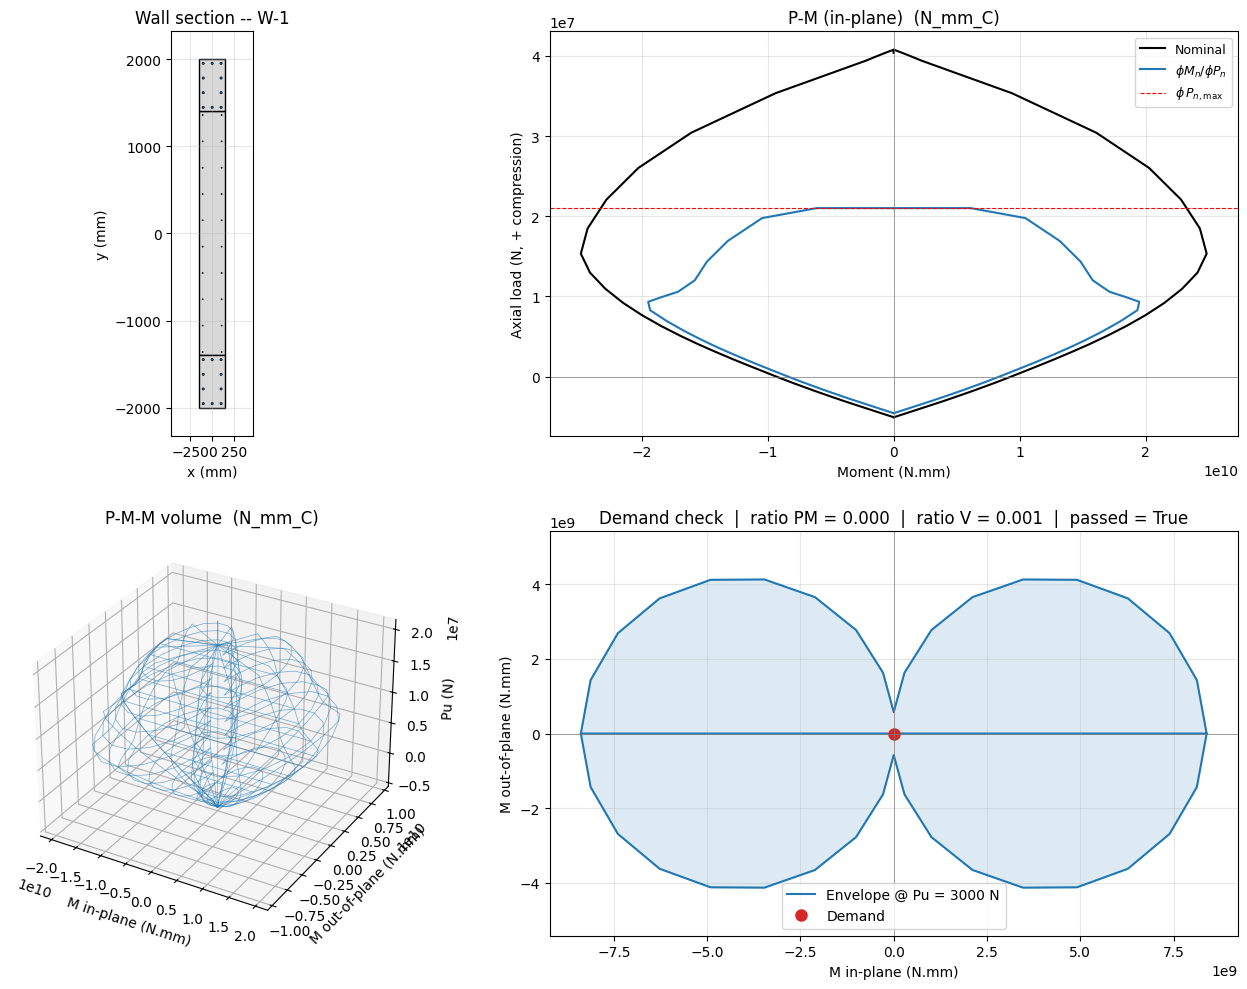

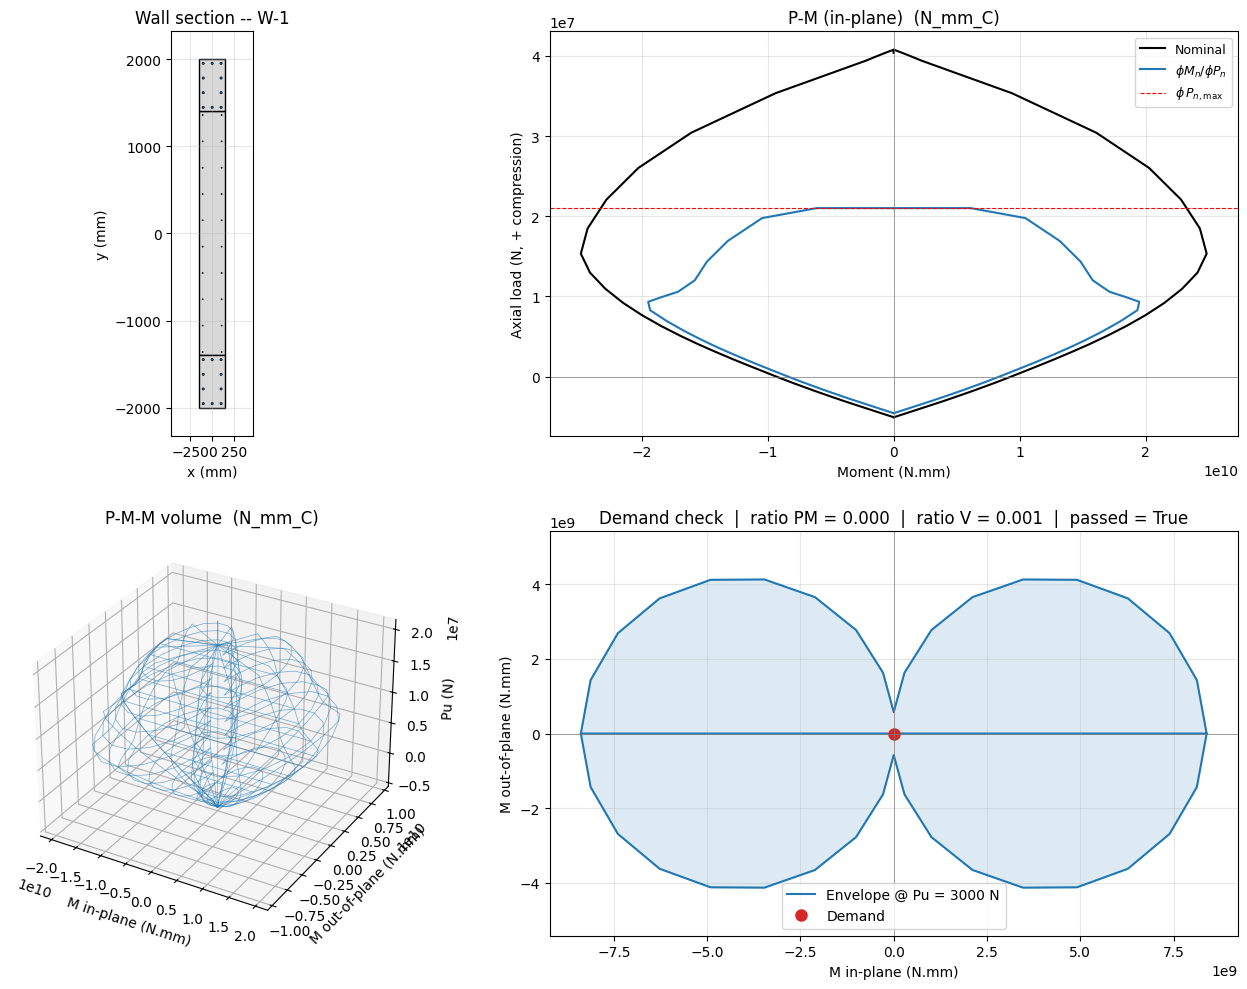

In [11]:
fig = wall.plot.dashboard(demands=demands)
fig

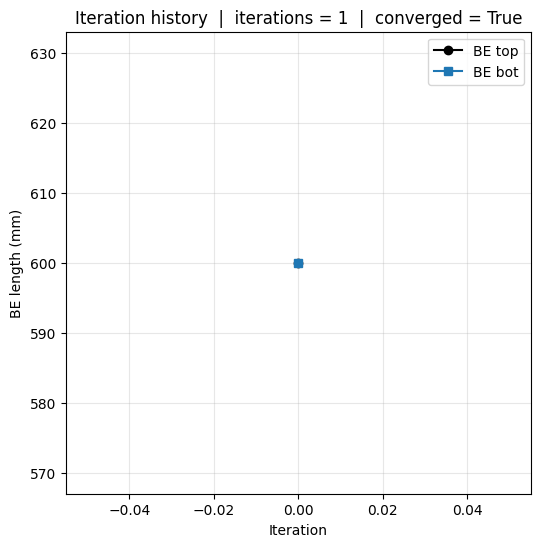

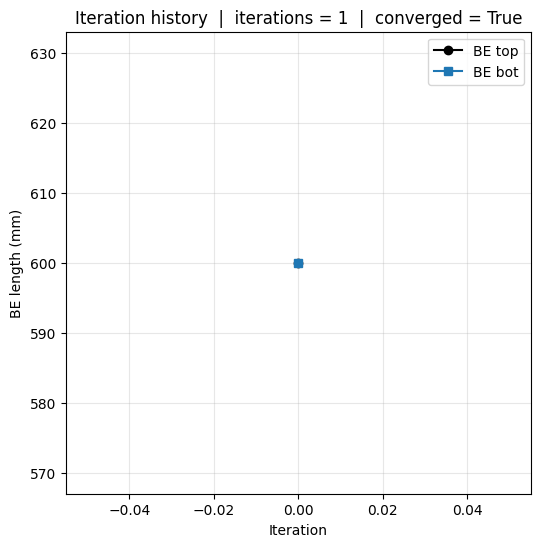

In [12]:
ax = wall.plot.iteration_history(results)
ax.figure

## Step 12 — `run_optimize(demands)`

In [13]:
alts = wall.run_optimize(demands)
print(f"{len(alts)} alternatives; best rho_total = {alts[0].rho_total:.1f} kg/m³")

442 alternatives; best rho_total = 73.0 kg/m³


---
### Architecture recap

Same 12 steps as beam and column. The wall adds the **iterative BE loop** and the **web + Column‑boundary‑element** composition; the BE detailing is delegated wholesale to the column engine.